# The graphs in `agents/`, rendered and exercised

Renders the compiled LangGraph graphs declared in `src/agentic_review/agents/` (ADR-0009, ADR-0010), then runs
each agent against scripted scenarios. There are two graphs:

| Graph | Builder | Shape |
|---|---|---|
| Pipeline (main agent) | `pipeline_agent.build_pipeline_graph` | acyclic, one node per CF phase |
| Review reporting agent (CF-6) | `review_reporting_agent.build_review_graph` | the only place a cycle may occur (repair edge) |

`review_port.py` declares no graph of its own: `LangGraphReviewPort` wraps the review graph and binds the
`emit_finding` tool.

| § | What | Calls a model? |
|---|---|---|
| 0 | Langfuse tracing, set once at boot | no |
| 1–3 | Render the two graphs | no |
| 4 | Test the review port and the review reporting agent | no — scripted stand-in |
| 5 | Test the pipeline agent end to end over a temporary git repository | no — scripted stand-in |
| 6 | Run the pytest suites for the same code | no |

**No model is called.** Sections 4 and 5 use `ScriptedChatModel` from `tests/support/`, which replays scripted
replies (or raises scripted errors) and drives the **real** graphs.

**Tracing.** When the Langfuse keys are available (VS Code loads `.env` into the kernel; otherwise §0 reads them from
it), every graph run in §4 and §5 is traced to Langfuse, tagged `scripted-model` so it is never mistaken for a real
review. Set `TRACE = False` in §0 to run with nothing leaving the machine.

## Setup

In [1]:
from IPython.display import Image, Markdown, display
from langchain_core.runnables import RunnableLambda

from agentic_review.agents.pipeline_agent import build_pipeline_graph
from agentic_review.agents.review_reporting_agent import build_review_graph


def show(compiled, title):
    """Render as PNG (mermaid.ink, needs network); fall back to the Mermaid source."""
    graph = compiled.get_graph()
    print(title, "| nodes:", list(graph.nodes), "| edges:", len(graph.edges))
    try:
        display(Image(graph.draw_mermaid_png()))
    except Exception as error:
        print(f"PNG render unavailable ({type(error).__name__}); Mermaid source below - paste into mermaid.live")
        print(graph.draw_mermaid())


## 0 · Langfuse tracing, set once at boot

`set_tracing_callback()` attaches **one** Langfuse `CallbackHandler` to every LangChain and LangGraph run in this
kernel, through LangChain's `register_configure_hook`, the mechanism a globally configured tracer uses. No
`.invoke()` or `.stream()` call below passes `config={"callbacks": [...]}`, and none of the product code changes.

| | |
|---|---|
| When | once, here, before anything else touches Langfuse |
| For | clean call sites: zero configuration on each `.invoke()` |
| Against | per-run metadata can't ride on the handler; it is set around each run with Langfuse's `propagate_attributes` (`traced(...)` below) instead |

**Why it must run first.** Langfuse keeps one client per public key, and the first one created decides whether
tracing is on. `load_instructions` (which `assemble` calls in §5 to fetch the managed system prompt) creates its
client with `tracing_enabled=False`. If that client came first, the handler below would export nothing.

In [ ]:
import os
from contextlib import nullcontext
from contextvars import ContextVar
from datetime import datetime
from pathlib import Path

from langchain_core.tracers.context import register_configure_hook

TRACE = True  # False: no handler is registered and nothing is sent to Langfuse

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SESSION_ID = "agents-notebook-" + datetime.now().strftime("%Y%m%d-%H%M%S")
TAGS = ["agents-notebook", "scripted-model"]


def load_langfuse_keys(env_file: Path) -> None:
    """Copy LANGFUSE_* from .env into the environment when the kernel did not load it. Nothing else is read."""
    if not env_file.is_file():
        return
    for line in env_file.read_text(encoding="utf-8").splitlines():
        key, sep, value = line.strip().partition("=")
        if sep and key.startswith("LANGFUSE_") and not os.environ.get(key):
            os.environ[key] = value.strip().strip('"').strip("'")


def set_tracing_callback():
    """Register one Langfuse handler for every LangChain/LangGraph run in this kernel. Returns it, or None.

    Idempotent: re-running this cell must not register a second hook, or every run would be traced twice.
    """
    existing = globals().get("TRACER")
    if existing is not None:
        return existing
    if not (os.environ.get("LANGFUSE_PUBLIC_KEY") and os.environ.get("LANGFUSE_SECRET_KEY")):
        print("Langfuse not configured: no tracing")
        return None
    from langfuse import get_client
    from langfuse.langchain import CallbackHandler

    if not get_client().auth_check():  # the first client for this key: tracing is enabled on it
        print("Langfuse auth check FAILED: no tracing")
        return None
    handler = CallbackHandler()
    # The handler is the ContextVar's *default*, not a value .set() in this cell: every later cell, thread and task
    # sees it without depending on how the kernel carries context from one cell to the next.
    register_configure_hook(ContextVar("notebook_langfuse_handler", default=handler), inheritable=True)
    return handler


def traced(name: str):
    """Trace-level attributes for the runs inside: one name per scenario, one session per notebook run."""
    if TRACER is None:
        return nullcontext()
    from langfuse import propagate_attributes

    return propagate_attributes(trace_name=name, session_id=SESSION_ID, tags=TAGS)


if TRACE:
    load_langfuse_keys(PROJECT / ".env")
    TRACER = set_tracing_callback()
else:
    TRACER = None
print("tracing:", f"on -> {os.environ.get('LANGFUSE_BASE_URL')} | session {SESSION_ID}" if TRACER else "off")

## 1 · Pipeline graph (main agent)

Fixed order, acyclic. `preflight` may route straight to the end.

pipeline | nodes: ['__start__', 'preflight', 'resolve_change_set', 'parse_and_context', 'execute_checks', 'load_patterns', 'assemble_context', 'review_agent', 'build_report', '__end__'] | edges: 11


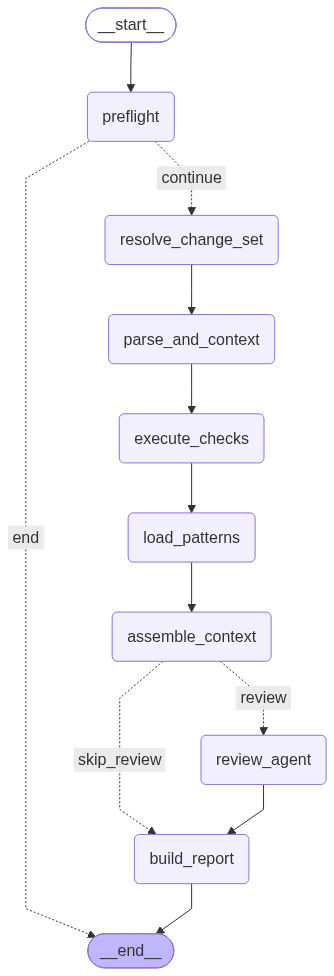

In [2]:
pipeline = build_pipeline_graph()
show(pipeline, 'pipeline')

## 2 · Review reporting agent graph (CF-6)

The `decide_repair` → `call_model` edge is the one permitted cycle.

review | nodes: ['__start__', 'call_model', 'validate_calls', 'record_coverage', 'decide_repair', '__end__'] | edges: 7


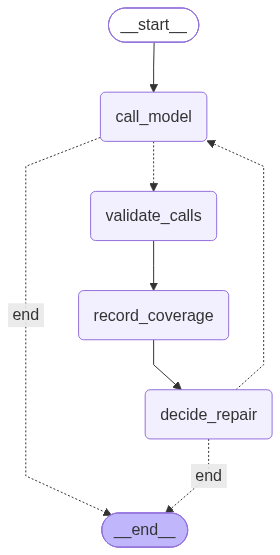

In [9]:
stand_in_model = RunnableLambda(lambda messages: None)  # never invoked; the graph only needs it to build
review = build_review_graph(stand_in_model)
show(review, 'review')

## 3 · Mermaid source

For pasting into docs (the repo's docs use mermaid).

In [12]:
fence = "`" * 3
for name, compiled in [("pipeline", pipeline), ("review", review)]:
    source = compiled.get_graph().draw_mermaid()
    display(Markdown("**" + name + "**" + chr(10)*2 + fence + "mermaid" + chr(10) + source + chr(10) + fence))

**pipeline**

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	preflight(preflight)
	resolve_change_set(resolve_change_set)
	parse_and_context(parse_and_context)
	execute_checks(execute_checks)
	load_patterns(load_patterns)
	assemble_context(assemble_context)
	review_agent(review_agent)
	build_report(build_report)
	__end__([<p>__end__</p>]):::last
	__start__ --> preflight;
	assemble_context --> review_agent;
	execute_checks --> load_patterns;
	load_patterns --> assemble_context;
	parse_and_context --> execute_checks;
	preflight -. &nbsp;end&nbsp; .-> __end__;
	preflight -. &nbsp;continue&nbsp; .-> resolve_change_set;
	resolve_change_set --> parse_and_context;
	review_agent --> build_report;
	build_report --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

**review**

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	call_model(call_model)
	validate_calls(validate_calls)
	record_coverage(record_coverage)
	decide_repair(decide_repair)
	__end__([<p>__end__</p>]):::last
	__start__ --> call_model;
	call_model -. &nbsp;end&nbsp; .-> __end__;
	call_model -.-> validate_calls;
	decide_repair -. &nbsp;end&nbsp; .-> __end__;
	decide_repair -.-> call_model;
	record_coverage --> decide_repair;
	validate_calls --> record_coverage;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

## 4 · Testing the review port and the review reporting agent

`ScriptedChatModel` returns the replies in its script in order. A scripted exception is raised instead of returned,
so provider failures can be staged too. Everything after the model call runs as shipped: validation, the repair
turn, the ceiling, the no-call rule, and completion status.

The pytest suites in `tests/unit/agents/` and `tests/integration/` are the authority. These cells are for looking
at the behaviour: which nodes ran, what the model was sent, what came out.

In [ ]:
import json
import os
import sys
import tempfile
import time
from dataclasses import replace
from pathlib import Path

import httpx
import openai
from IPython.display import Markdown, display
from langchain_core.tools import BaseTool
from langchain_core.utils.function_calling import convert_to_openai_tool
from rich.console import Console

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))  # so `tests.support` imports

from agentic_review.agents.pipeline_agent import (
    PipelineDeps,
    PipelineRun,
    ReviewRequest,
    Reviewed,
    utc_now,
)
from agentic_review.agents.review_port import build_review_port, emit_finding
from agentic_review.agents.review_reporting_agent import build_review_graph, finish, start_run
from agentic_review.core.assembly.prompt import INSTRUCTIONS, MATERIAL_STATEMENT, load_instructions
from agentic_review.core.config.credentials import Credential, credential_sources
from agentic_review.core.config.settings import AgentSettings
from agentic_review.core.findings.port import ReviewContext, ReviewedFile, RunMaterial
from agentic_review.core.output.terminal import render_terminal
from agentic_review.core.pipeline.preflight import PreflightFailure
from tests.support.repo_builder import RepoBuilder
from tests.support.scripted_chat_model import ScriptedChatModel, ai_reply, finding_call, invalid_json_call

FAKE_KEY = "nb-fake-key-never-sent"  # the stand-in model never uses it
REQUEST = httpx.Request("POST", "https://example.invalid/v1/chat/completions")

# The Langfuse-managed prompt when configured, else the built-in INSTRUCTIONS. Runs after §0, so the tracing
# client already exists and this prompt-only client cannot switch tracing off.
sys_prompt = load_instructions(os.environ)

CONTEXT = ReviewContext(
    instructions=sys_prompt.text,
    material_statement=MATERIAL_STATEMENT,
    diff_section="src/app.ts (modified)\n[hunk 0] @@ -1 +1 @@\n-a\n+b\n",
    estimated_tokens=40,
    material=RunMaterial(reviewed_files={"src/app.ts": ReviewedFile(line_count=40, hunk_count=2)}),
)
TWO_FILES = replace(
    CONTEXT,
    material=RunMaterial(
        reviewed_files={
            "src/app.ts": ReviewedFile(line_count=40, hunk_count=2),
            "src/other.ts": ReviewedFile(line_count=10, hunk_count=1),
        }
    ),
)


def make_port(script, **agent):
    """A real LangGraphReviewPort around the stand-in model. ``agent`` takes AgentSettings keys, camelCase."""
    model = ScriptedChatModel(script)
    credential = Credential(FAKE_KEY, source="environment", location="AGENTIC_REVIEW_API_KEY")
    return build_review_port(AgentSettings.model_validate(agent), credential, chat_model=model), model


def connection_error():
    return openai.APIConnectionError(message="could not reach host", request=REQUEST)


def rate_limited():
    return openai.RateLimitError("slow down", response=httpx.Response(429, request=REQUEST), body=None)


print("stand-in ready | tracing:", "on" if TRACER else "off", "| system prompt:", sys_prompt.source,
      f"(fell back: {sys_prompt.problem})" if sys_prompt.problem else "")

### 4.1 · The bound tool (`review_port.py`)

What `LangGraphReviewPort` hands to `bind_tools`: exactly one tool, the `@tool`-declared `emit_finding`, with no
`tool_choice` (FR-5.10). `convert_to_openai_tool` is the conversion `ChatOpenAI.bind_tools` applies, so this is
what the provider receives.

In [ ]:
port, model = make_port([ai_reply()])
with traced("agents-nb 4.1 bound tool"):
    port.review(CONTEXT)

assert model.bound_tools is not None and len(model.bound_tools) == 1
bound = model.bound_tools[0]
assert isinstance(bound, BaseTool) and bound is emit_finding
assert model.bound_kwargs is not None and "tool_choice" not in model.bound_kwargs

function = convert_to_openai_tool(bound)["function"]
parameters = function["parameters"]
print("name:       ", function["name"])
print("parameters: ", list(parameters["properties"]))
print("required:   ", parameters["required"])
print("evidence:   ", [arm["properties"]["kind"]["const"] for arm in parameters["properties"]["evidence"]["oneOf"]])
print("\ndescription:\n" + function["description"])

# The tool is declared for binding only: the graph's validate_calls node answers every call.
try:
    emit_finding.invoke(finding_call()["args"])
except NotImplementedError as error:
    print("\ninvoking it directly ->", type(error).__name__ + ":", error)

### 4.2 · One run, node by node (`review_reporting_agent.py`)

`graph.stream(..., stream_mode="updates")` yields one update per node as it runs, so the path shows whether the
repair edge `decide_repair → call_model` was taken. Here the first reply's call names line 99 of a 40-line file, is
rejected, and the one repair turn corrects it.

In [ ]:
def trace(script, context=CONTEXT, ceiling=None):
    """Build the review graph as the port does and stream it; returns (path, completion, degradations, run)."""
    model = ScriptedChatModel(script)
    graph = build_review_graph(model.bind_tools([emit_finding]), rate_limit_retry_seconds=0)
    run = start_run(context, ceiling=ceiling)
    path = [node for update in graph.stream({"run": run}, stream_mode="updates") for node in update]
    completion, degradations = finish(run)
    return path, completion, degradations, run


with traced("agents-nb 4.2 repair turn, node by node"):
    path, completion, degradations, run = trace(
        [ai_reply([finding_call(startLine=99, endLine=99)]), ai_reply([finding_call()])]
    )
print("path:      ", " -> ".join(path))
print("completion:", completion, "| degradations:", [d.code for d in degradations])
print("findings:  ", [(f.id, f.severity, f"turn {f.turn_index}") for f in run.accounting.findings])
assert path.count("call_model") == 2 and completion == "emitted"

print("\nthe conversation the model saw:")
for message in run.messages:
    text = message.content if isinstance(message.content, str) else json.dumps(message.content)
    calls = getattr(message, "tool_calls", None)
    detail = f"{len(calls)} tool call(s)" if calls else " ".join(text.split())[:110]
    print(f"  {type(message).__name__:13} {detail}")

### 4.3 · Scenarios

Each row scripts the model's replies and states what the review must report. The **Model calls** column counts the
replies consumed: a second call means the repair turn (or the 429 retry) happened. Every row is asserted.

In [ ]:
SCENARIOS = {
    # name: (script, context, AgentSettings overrides, completion, degradation codes, model calls)
    "one valid finding": ([ai_reply([finding_call()])], CONTEXT, {}, "emitted", [], 1),
    "several findings in one reply": (
        [ai_reply([finding_call(severity="nit"), finding_call(startLine=5, endLine=6, severity="blocking")])],
        CONTEXT, {}, "emitted", [], 1,
    ),
    "no tool call": ([ai_reply(content="Looks fine to me.")], CONTEXT, {}, "no-tool-call", ["no-tool-call"], 1),
    "finding-like JSON in prose is ignored": (
        [ai_reply(content=json.dumps(finding_call()["args"]))], CONTEXT, {}, "no-tool-call", ["no-tool-call"], 1,
    ),
    "rejected, corrected in the repair turn": (
        [ai_reply([finding_call(startLine=99, endLine=99)]), ai_reply([finding_call()])], CONTEXT, {}, "emitted", [], 2,
    ),
    "rejected twice": (
        [ai_reply([finding_call(startLine=99, endLine=99)]), ai_reply([finding_call(startLine=99, endLine=99)])],
        CONTEXT, {}, "invalid-model-output", ["invalid-model-output"], 2,
    ),
    "invalid JSON arguments, then corrected": (
        [ai_reply(invalid_tool_calls=[invalid_json_call()]), ai_reply([finding_call()])], CONTEXT, {}, "emitted", [], 2,
    ),
    "unknown tool name": (
        [ai_reply([finding_call(name="run_tests")]), ai_reply([finding_call()])], CONTEXT, {}, "emitted", [], 2,
    ),
    "ceiling of 2, three calls": (
        [ai_reply([finding_call(startLine=n, endLine=n) for n in (1, 2, 3)])],
        CONTEXT, {"toolCallCeiling": 2}, "ceiling-reached", ["tool-budget-exhausted"], 1,
    ),
    "a reviewed file never named": (
        [ai_reply([finding_call()]), ai_reply()], TWO_FILES, {}, "emitted", ["incomplete-file-coverage"], 2,
    ),
    "coverage repair names the file": (
        [ai_reply([finding_call()]), ai_reply([finding_call(file="src/other.ts")])], TWO_FILES, {}, "emitted", [], 2,
    ),
    "provider unreachable": ([connection_error()], CONTEXT, {}, "provider-error", ["provider-error"], 1),
    "429, retry succeeds": (
        [rate_limited(), ai_reply([finding_call()])], CONTEXT, {"rateLimitRetrySeconds": 0},
        "emitted", ["provider-error"], 2,
    ),
    "429 twice": (
        [rate_limited(), rate_limited()], CONTEXT, {"rateLimitRetrySeconds": 0}, "provider-error", ["provider-error"], 2,
    ),
    "content filter": (
        [ai_reply([finding_call()], finish_reason="content_filter")], CONTEXT, {}, "provider-error", ["provider-error"], 1,
    ),
    "provider fails on the repair turn": (
        [ai_reply([finding_call(), finding_call(startLine=99, endLine=99)]), connection_error()],
        CONTEXT, {}, "emitted", ["invalid-model-output", "provider-error"], 2,
    ),
}

rows, failures = [], []
for name, (script, context, agent, want_status, want_codes, want_calls) in SCENARIOS.items():
    port, model = make_port(script, **agent)
    with traced(f"agents-nb 4.3 {name}"):
        outcome = port.review(context)  # never raises, whatever the script does (FR-11.2)
    got = (outcome.completion_status, sorted(d.code for d in outcome.degradations), model.call_count)
    ok = got == (want_status, sorted(want_codes), want_calls)
    if not ok:
        failures.append(f"{name}: got {got}")
    findings = ", ".join(f"{f.id}:{f.severity}@t{f.turn_index}" for f in outcome.findings) or "—"
    codes = ", ".join(got[1]) or "—"
    rows.append(f"| {'✅' if ok else '❌'} | {name} | `{got[0]}` | {codes} | {findings} | {got[2]} | {outcome.repair_turns} |")

display(Markdown(
    "| | Scenario | Completion | Degradations | Findings | Model calls | Repair turns |\n"
    "|---|---|---|---|---|---|---|\n" + "\n".join(rows)
))
assert not failures, failures
print(f"{len(SCENARIOS)} scenarios passed")

## 5 · Testing the pipeline agent (`pipeline_agent.py`)

The whole fixed order over a real temporary git repository: `preflight → resolve_change_set → … → build_report`.
Only the model is scripted — the port factory hands the pipeline a real `LangGraphReviewPort` around the stand-in.
The credential is a fake key in the environment passed to preflight; it is never sent anywhere. With Langfuse
configured, `assemble` fetches the managed system prompt, as the CLI does; the scripted replies don't read it.

The repository is built with `RepoBuilder` from `tests/support/`: one committed file, then an uncommitted edit to
every line of it.

In [ ]:
WORKDIR = Path(tempfile.mkdtemp(prefix="agents-nb-"))
repo = RepoBuilder(WORKDIR / "repo").init()
repo.write("src/app.ts", "".join(f"export const v{i} = {i};\n" for i in range(1, 21)))
repo.commit("initial")
repo.write("src/app.ts", "".join(f"export const v{i} = {i * 2};\n" for i in range(1, 21)))

ENV = {**os.environ, "AGENTIC_REVIEW_API_KEY": FAKE_KEY}


def run_pipeline(cwd, script, name):
    """``run_review``, but streamed through the same compiled graph so the node path is visible."""
    model = ScriptedChatModel(script)
    run = PipelineRun(request=ReviewRequest(cwd=cwd), clock=time.monotonic, now=utc_now)
    deps = PipelineDeps(
        credentials=credential_sources(ENV),
        port_factory=lambda settings, credential: build_review_port(settings, credential, chat_model=model),
    )
    with traced(f"agents-nb {name}"):
        stream = pipeline.stream({"run": run}, context=deps, stream_mode="updates")
        path = [node for update in stream for node in update]
    return path, run.result, model


print("repository:", repo.root)
print(repo.git("status", "--short"))

### 5.1 · A review with findings

Every node runs, `review_agent` once. The report is rendered by the same renderer the CLI uses.

In [ ]:
path, result, model = run_pipeline(
    repo.root,
    [ai_reply([finding_call(startLine=2, endLine=2, severity="blocking"), finding_call(startLine=7, endLine=7, severity="nit")])],
    "5.1 pipeline with findings",
)
print("path:", " -> ".join(path))
assert isinstance(result, Reviewed), result
report = result.report
assert path[-1] == "build_report" and "review_agent" in path and model.call_count == 1
assert report.run.completion_status == "emitted" and len(report.findings) == 2
print("verdict:", report.verdict, "| completion:", report.run.completion_status, "| stages:", report.run.stage_durations_ms)

render_terminal(report, Console(width=120))

### 5.2 · Over budget: the review node is skipped

With `budget.maxTokens: 10` the assembled prompt cannot fit. `assemble_context` routes straight to `build_report`,
the model is never called, and the report says so (FR-11.2) rather than claiming a clean review.

In [ ]:
repo.write(".agentic-review.yml", "schemaVersion: 1\nbudget:\n  maxTokens: 10\n")
try:
    path, result, model = run_pipeline(repo.root, [], "5.2 pipeline over budget")  # empty script: a model call would fail
finally:
    (repo.root / ".agentic-review.yml").unlink()

print("path:", " -> ".join(path))
assert isinstance(result, Reviewed) and "review_agent" not in path and model.call_count == 0
report = result.report
assert report.run.completion_status == "budget-exhausted" and report.run.budget_hit
print("verdict:", report.verdict, "| completion:", report.run.completion_status)
for degradation in report.degradations:
    print(f"{degradation.source} {degradation.code}: {degradation.detail}")

### 5.3 · Preflight failure: the only stage that may stop the run

Pointed at a directory that is not a git repository, `preflight` routes to the end. No report is built.

In [ ]:
not_a_repo = WORKDIR / "not-a-repo"
not_a_repo.mkdir(exist_ok=True)
path, result, model = run_pipeline(not_a_repo, [], "5.3 pipeline preflight failure")

print("path:", " -> ".join(path))
assert path == ["preflight"] and isinstance(result, PreflightFailure) and model.call_count == 0
print("PreflightFailure:", result.message)

## 6 · The pytest suites for the same code

The authoritative tests for `agents/`: the unit tests for the review graph and port, and the two integration
stories that drive the pipeline agent. Runs offline in the project's environment.

In [ ]:
import subprocess

completed = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider",
     "tests/unit/agents", "tests/integration/test_story1_review_uncommitted.py",
     "tests/integration/test_story2_failure_modes.py"],
    cwd=PROJECT, capture_output=True, text=True,
)
print(completed.stdout[-2500:] or completed.stderr[-2500:])
assert completed.returncode == 0

## 7 · Flush the traces

The handler exports in the background; `flush()` sends whatever is still queued before you go looking. In Langfuse,
filter by the session id printed below, or by the tag `agents-notebook`.

In [ ]:
if TRACER is None:
    print("tracing was off: nothing to flush")
else:
    from langfuse import get_client

    client = get_client()
    client.flush()
    print("flushed | session:", SESSION_ID, "| tags:", TAGS)
    if TRACER.last_trace_id:
        print("last trace:", client.get_trace_url(trace_id=TRACER.last_trace_id))